# Role Mining — Part A: User × Entitlement Matrix
**Keystone Fuel & Market (synthetic data) · Snapshot T0 · Seed 2026**

Goal: reshape access assignments into a person × entitlement matrix, measure how access is spread, and find candidate birthright access by department.

In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "t0"
IMG = ROOT / "reports" / "img"
IMG.mkdir(parents=True, exist_ok=True)
print("Reading data from:", DATA)

Reading data from: c:\Users\metzg\Documents\entra-governance\data\t0


In [5]:
hr = pd.read_csv(DATA / "hr_feed.csv")
assignments = pd.read_csv(DATA / "entitlement_assignments.csv")
catalog = pd.read_csv(DATA / "entitlement_catalog.csv")

print("HR records:      ", hr.shape)
print("Assignments:     ", assignments.shape)
print("Entitlements:    ", catalog.shape)

HR records:       (300, 12)
Assignments:      (1641, 4)
Entitlements:     (35, 5)


In [6]:
print(hr["status"].value_counts())
print()
print(hr["department"].value_counts())

status
Active        276
Terminated     24
Name: count, dtype: int64

department
Store Operations          171
Information Technology     38
Human Resources            20
Finance                    20
Fuel Operations            18
Procurement                18
Payments / PCI             15
Name: count, dtype: int64


In [7]:
joined = assignments.merge(
    hr[["upn", "employee_id", "department", "job_title", "status"]],
    on="upn", how="left", indicator=True)

print(joined["_merge"].value_counts())
no_hr = joined[joined["_merge"] == "left_only"]
print("Assignments with no HR record:", len(no_hr), "across", no_hr["upn"].nunique(), "accounts")

_merge
both          1584
left_only       57
right_only       0
Name: count, dtype: int64
Assignments with no HR record: 57 across 16 accounts


In [8]:
active = joined[(joined["_merge"] == "both") & (joined["status"] == "Active")].copy()
print("Assignments kept for mining:", len(active))
print("People:", active["upn"].nunique(), "| Entitlements:", active["entitlement"].nunique())

Assignments kept for mining: 1472
People: 276 | Entitlements: 35


In [9]:
matrix = pd.crosstab(active["upn"], active["entitlement"]).clip(upper=1)
print("Matrix shape (people x entitlements):", matrix.shape)
print("Total 1s in the matrix:", int(matrix.values.sum()))
print(f"Fill rate: {matrix.values.mean():.1%}")
matrix.iloc[:5, :6]

Matrix shape (people x entitlements): (276, 35)
Total 1s in the matrix: 1472
Fill rate: 15.2%


entitlement,APP-ERP-Read,APP-Email,APP-LearningPortal,APP-Timeclock,Chargeback-Approve,Chargeback-Edit
upn,,,,,,
alex.castillo@kqm-lab.example,0,1,1,1,0,0
alex.kowalski@kqm-lab.example,0,1,1,1,0,0
alex.larsen@kqm-lab.example,0,1,1,1,0,0
alex.mensah@kqm-lab.example,0,1,0,0,0,0
alex.miller@kqm-lab.example,0,1,0,0,0,1


In [10]:
per_user = matrix.sum(axis=1)
print(per_user.describe().round(1))

count    276.0
mean       5.3
std        1.7
min        3.0
25%        4.0
50%        5.0
75%        7.0
max       11.0
dtype: float64


In [11]:
per_ent = matrix.sum(axis=0).sort_values(ascending=False)
print("Most-held entitlements:"); print(per_ent.head(5)); print()
print("Least-held entitlements:"); print(per_ent.tail(5))

Most-held entitlements:
entitlement
APP-Email             276
APP-Timeclock         195
APP-LearningPortal    180
POS-Cashier           117
SafeCount-Operator     66
dtype: int64

Least-held entitlements:
entitlement
ERP-VendorPayment-Create    9
FuelPricing-View            9
TankMonitor-Operator        7
Chargeback-Edit             4
Payments-Gateway-Read       3
dtype: int64


In [12]:
dept_of = active.drop_duplicates("upn").set_index("upn")["department"]
prevalence = matrix.groupby(dept_of.reindex(matrix.index)).mean()
prevalence.round(2).T.head(10)

department,Finance,Fuel Operations,Human Resources,Information Technology,Payments / PCI,Procurement,Store Operations
entitlement,,,,,,,
APP-ERP-Read,1.00,0.00,0.06,0.03,0.07,1.00,0.01
APP-Email,1.00,1.00,1.00,1.00,1.00,1.00,1.00
APP-LearningPortal,0.20,0.12,0.29,0.09,0.29,0.25,1.00
APP-Timeclock,0.20,1.00,0.29,0.06,0.29,0.31,1.00
Chargeback-Approve,0.00,0.00,0.00,0.00,0.86,0.00,0.00
Chargeback-Edit,0.00,0.00,0.00,0.00,0.14,0.00,0.01
Directory-Admin,0.05,0.00,0.00,0.35,0.00,0.00,0.01
Directory-PasswordReset,0.00,0.00,0.00,0.32,0.00,0.00,0.00
Directory-Read,0.00,0.06,0.00,0.32,0.00,0.06,0.00


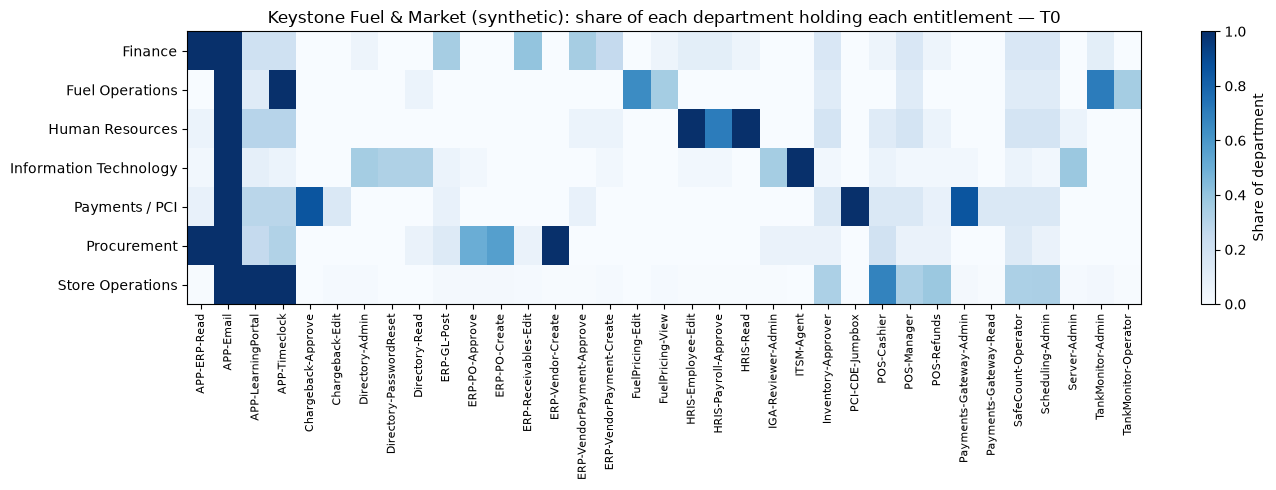

In [13]:
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(prevalence.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(prevalence.index)), prevalence.index)
ax.set_xticks(range(len(prevalence.columns)), prevalence.columns, rotation=90, fontsize=8)
ax.set_title("Keystone Fuel & Market (synthetic): share of each department holding each entitlement — T0")
fig.colorbar(im, ax=ax, label="Share of department")
fig.tight_layout()
fig.savefig(IMG / "m2-dept-entitlement-heatmap-t0.png", dpi=150)
plt.show()

In [14]:
birthright_candidates = prevalence.stack().rename("share").reset_index()
birthright_candidates = birthright_candidates[birthright_candidates["share"] >= 0.90]
print("Department/entitlement pairs held by 90%+ of the department:", len(birthright_candidates))
birthright_candidates.sort_values(["department", "share"], ascending=[True, False])

Department/entitlement pairs held by 90%+ of the department: 17


,department,entitlement,share
0,Finance,APP-ERP-Read,1.0
1,Finance,APP-Email,1.0
36,Fuel Operations,APP-Email,1.0
38,Fuel Operations,APP-Timeclock,1.0
71,Human Resources,APP-Email,1.0
88,Human Resources,HRIS-Employee-Edit,1.0
90,Human Resources,HRIS-Read,1.0
106,Information Technology,APP-Email,1.0
127,Information Technology,ITSM-Agent,1.0
141,Payments / PCI,APP-Email,1.0


## Findings (T0)
- __ active employees hold __ entitlements through __ assignments; the matrix is __% filled.
- __ assignments (__ accounts) have no HR record and were excluded from mining — they are cleanup work, not role input.
- __ department/entitlement pairs are held by 90%+ of a department (birthright candidates).
- Not every 90%+ pair should become automatic access: __ (name one, and say why).
- Next: cluster people by similar access (M2.2) — department alone is too coarse because __.